# Individual Province Calibration

In [1]:
import zoonosim as zn
import numpy as np
import seaborn as sns
import pandas as pd
import optuna as op
import matplotlib.pyplot as plt
from scipy import stats
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
import sklearn
import json
import plotly

Zoonosim 0.0.2 (2026-03-03) — © 2025 by McGill University


In [2]:
project_name = "provincial_calibration_1"
zn.options.set(verbose=0) # How much output to print to the console (0 = none, 1 = some, 2 = all)
zn.options.set(numba_parallel='safe') # Whether to use parallel processing for numba-compiled functions. Options are 'safe', 'force', or 'off'.
zn.options.set(numba_cache=False) # Whether to cache numba-compiled functions to disk. Options are True or False.

Reloading Zoonosim so changes take effect...
Reload complete. Note: for some options to take effect, you may also need to delete Zoonosim's __pycache__ folder.
Reloading Zoonosim so changes take effect...
Reload complete. Note: for some options to take effect, you may also need to delete Zoonosim's __pycache__ folder.


In [3]:

baseline_pars = dict(
    # Peliminary parameters
    rand_seed = 17, # Random seed for the simulation. This is used to ensure that the results are reproducible.
    pop_scale = 1.0, # Scale factor for the population size. This is a vestigial parameter that is no longer used, but is kept for compatibility with older code.
    rescale = False, # Whether to rescale the population size to match the pop_size parameter. This is a vestigial parameter that is no longer used, but is kept for compatibility with older code.
    record_all_events = False, # Whether to record all events in the simulation. We set it to False during calibration to save memory.
    verbose = zn.options.get('verbose'), # How much output to print to the console (0 = none, 1 = some, 2 = all)

    # Simulation parameters

    agent_types = ['human', 'ppe', 'flock', 'barn', 'water'],
    n_farms = 50,
    pop_size = None, # This gets filled in when the population is generated
    pop_size_by_type = {}, # This gets filled in when the population is generated
    pop_pars = dict( # Parameters used for generating the population
        avg_barns_per_farm = 4.0, # Average number of barns per farm. Used to define the number of barns in the population. The actual number of barns per farm is drawn from a Poisson distribution with this mean.
        avg_humans_per_barn = 1.0, # We define the number of humans per barn rather than per farm to ensure larger farms have more humans. The actual number of humans per barn is drawn from a Poisson distribution with this mean.
        avg_water_per_farm = 0.75, # Average number of water sources per farm. The actual number of water sources per farm is drawn from a Poisson distribution with this mean. This value should be less than 1.0 to ensure that some farms share water sources.
        number_of_transients = 3, # Number of transient agents in the population. These are agents that move between farms and can spread disease between them.
        visits_per_day = 3, # Number of farms each transient visits in a day
    ),

    initial_conditions = dict( # dictates how many of each agent type are initially infected at the start of the simulation
        human = 0,
        ppe = 0,
        flock = 0,
        barn = 0,
        water = 0
    ),
    start_day = '2022-01-01', # The earliest day that we have data to calibrate the model to. This is used to set the start day of the simulation.
    end_day = '2025-12-31', # The latest day that we have data to calibrate the model to. This is used to set the end day of the simulation.
    n_days = None, # The number of days to run the simulation. If None, it will be set to the number of days between start_day and end_day.
    n_beds_hosp = None, # The number of hospital beds available in the population. If None, there is no restriction.
    no_hosp_factor = 1.0, # Change in mortality rate if hospital beds are not available. This is a multiplicative factor applied to the baseline mortality rate.
    beta = dict( # Beta values for each agent type.
        human = 0.0,
        ppe = 0.0,
        flock = 0.0,
        barn = 0.0,
        water = 0.0,
    ),
    n_imports = dict(
        human=None,  # Number of imported human cases per day; None = disabled
        flock=None,  # Number of imported flock cases per day; None = disabled
        ppe = None,   # Number of imported PPE contaminations per day; None = disabled
        barn=dict(import_pattern='seasonal', max_import_rate=0.2, peak_day=300),  # Number of imported barn contaminations per day; None = disabled
        water=dict(import_pattern='seasonal', max_import_rate=0.2, peak_day=300),  # Number of imported water contaminations per day; None = disabled
    ),
    transmission_pars = dict(
        human = dict(
                # beta_dist = dict(dist='neg_binomial', par1=1.0, par2=0.45, step=0.01), # Distribution to draw individual level transmissibility
                beta_dist = None,
                viral_loads = dict(minimum_load=3, peak_load=6),
                viral_levels = dict(min_scl=0.25, max_scl=1.0), # Specifies the range within which viral load should be scaled so it can contribute to relative transmissibility
                gamma_pars = dict(shape=2.0, scale=0.35) # Parameters for the gamma distribution used to determine the moment when an agents viral load exceeds the minimum detectable load.
        ),
        ppe = dict(
            # beta_dist = dict(dist='neg_binomial', par1=1.0, par2=0.45, step=0.01)
            beta_dist = None
        ),
        flock = dict(
            # beta_dist = dict(dist='neg_binomial', par1=1.0, par2=0.45, step=0.01)
            beta_dist = None
        ),
        barn = dict(
           # beta_dist = dict(dist='neg_binomial', par1=1.0, par2=0.45, step=0.01)
           beta_dist = None
        ),
        water = dict(
           # beta_dist = dict(dist='neg_binomial', par1=1.0, par2=0.45, step=0.01)
           beta_dist = None
        )
    ),
    immunity_pars = dict(
        human = dict(
        use_waning = True,
        nab_init = dict(dist='normal', par1=0, par2=2),  # Parameters for the distribution of the initial level of log2(nab) following natural infection, taken from fig1b of https://doi.org/10.1101/2021.03.09.21252641
        nab_decay = dict(form='nab_growth_decay', growth_time=21, decay_rate1=np.log(2) / 50, decay_time1=150, decay_rate2=np.log(2) / 250, decay_time2=365), # NOTE: I have no idea where this comes from
        nab_kin = None, # Constructed during sim initialization using the nab_decay parameters
        nab_boost = 1.5, # Multiplicative factor applied to a person's nab levels if they get reinfected.
        nab_eff = dict(alpha_inf=1.08, alpha_inf_diff=1.812, beta_inf=0.967, alpha_symp_inf=-0.739, beta_symp_inf=0.038, alpha_sev_symp=-0.014, beta_sev_symp=0.079), # Parameters to map nabs to efficacy
        rel_imm_symp = dict(asymp=0.85, mild=1, severe=1.5), # Relative immunity from natural infection varies by symptoms.
        immunity = None, # Matrix of immunity and cross-immunity factors, set by init_immunity() in immunity.py
        trans_redux = 0.59 # Reduction in transmission for breakthrough infection
        ),
        ppe = dict(use_waning = False),
        flock = dict(use_waning = False),
        barn = dict(use_waning = False),   
        water = dict(use_waning = False)
    ),
    dur = dict(
        human = dict(        # Duration: disease progression
            exp2inf = dict(dist='lognormal_int', par1=4.0, par2=2.0), # Duration from exposed to infectious
            inf2sym = dict(dist='lognormal_int', par1=4.0, par2=2.0), # Duration from infectious to symptomatic
            sym2sev = dict(dist='lognormal_int', par1=2.0, par2=1.0), # Duration from symptomatic to severe symptoms

            # Duration: Recovery
            asym2rec = dict(dist='lognormal_int', par1=8.0,  par2=2.0), # Duration for asymptomatic people to recover
            mild2rec = dict(dist='lognormal_int', par1=8.0,  par2=3.0), # Duration for people with mild symptoms to recover
            sev2rec = dict(dist='lognormal_int', par1=5.0, par2=3.0), # Duration for people with severe symptoms to recover
            sev2die = dict(dist='lognormal_int', par1=5.0, par2=3.0), # Duration from critical symptoms to death, 18.8 days total

            # Duration: quarantine
            quar = 7,
            # Duration: diagnosis
            diag = 14
        ),
        ppe = dict(        
            contamination = dict(dist='lognormal_int', par1=5.0, par2=3.0), # Duration of contamination.
            quar = 7, # Duration of quarantine after suspected exposure. NOTE: This should generally be the same as the human quarantine duration.
        ),
        flock = dict(
            # Duration: disease progression
            exp2inf = dict(dist='lognormal_int', par1=2.0, par2=1.0), # Duration from exposed to infectious. 
            inf2out = dict(dist='lognormal_int', par1=5.0, par2=2.0), # Duration from infectious to recovery/removal.
            susp2res = dict(dist='lognormal_int', par1=1.0, par2=0.25), # Duration from suspicion to a definitive test result. 

            # Duration: Quarantine
            quar = 14
        ),
        barn = dict(
            contamination = dict(dist='lognormal_int', par1=5, par2=3), # Duration of contamination. 
            composting = dict(dist='lognormal_int', par1=7.0, par2=1.5), # Duration of composting. 
            cleaning = dict(dist='lognormal_int', par1=7.0, par2=1.5), # Duration of cleaning process. 
        ),
        water = dict(
             contamination = dict(dist='lognormal_int', par1=5.0, par2=3.0), # Duration of contamination. 
        )
    ),
    poultry_pars = dict(
        breeds = np.array(['poultry'], dtype=zn.default_str),
        breed_freqs = np.array([1.0]),
        mortality_suspicion_threshold = [0.002], # I.E a deviation from the expected mortality rate of 0.01*expected_value will trigger suspicion
        symptomatic_suspicion_threshold = [0.002], # I.E a deviation from the expected symptomatic rate of 0.01*expected_value will trigger suspicion
        consumption_suspicion_threshold = [0.002], # I.E a deviation from the expected rate of water consumption of 0.01*expected_value will trigger suspicion
        cycle_dur = [dict(dist = 'normal_pos', par1 = 100, par2 = 25)],
        flock_size = [dict(dist = 'normal_pos', par1 = 25000, par2 = 10000)]
    ),
    prognoses = dict(
        human = dict(
            age_cutoffs   = np.array([0]),     # Age cutoffs (lower limits)
            sus_ORs       = np.array([1.00]),    # Odds ratios for relative susceptibility 
            trans_ORs     = np.array([0.00]),    # Odds ratios for relative transmissibility
            comorbidities = np.array([1.00]),    # Comorbidities by age -- set to 1 by default since already included in disease progression rates
            symp_probs    = np.array([0.96]),    # relative probability of developing symptoms 
            severe_probs  = np.array([0.38]),     # relative probability of developing severe symptoms
            death_probs   = np.array([0.02]),    # relative probability of dying
        ),
        ppe = dict(
            sus_ORs = np.array([1.00]),
            trans_ORs = np.array([1.00]),
        ),
        flock = dict(
            breeds = np.array(['poultry'], dtype=zn.default_str),
            sus_ORs = np.array([1.00]),
            trans_ORs = np.array([1.00]),
            baseline_symptomatic_rate = np.array([0.001]),
            infected_symptomatic_rate = np.array([1.00]),
            baseline_mortality_rate = np.array([0.001]),
            baseline_water_rate = np.array([1.00]),
            water_rate_increase = np.array([0.20])
        ),
        barn = dict(
            sus_ORs = np.array([1.00]),
            trans_ORs = np.array([1.00]),
        ),
        water = dict(
            sus_ORs = np.array([0.00]),
            trans_ORs = np.array([1.00]),
        )
    ),

    # Smartwatch parameters
    enable_smartwatches = False,
    # smartwatch_pars = dict(
    #     who                       = 'all', # Must be one of 'all', 'permanent', 'transient'; controls who receives smartwatches
    #     mean_fpr                  =   0.08, # mean false positive rate
    #     use_variable_fpr          = True, # Whether to use a variable false positive rate
    #     day_i                     = np.arange(-21, 22, 1), #
    #     loc                       = 3.25, # Day of max probability of alert, relative to the day of symptom onset.
    #     alpha                     = 1, # Scales the probability of receiving an alert
    #     usage_rate                = 1, # Out of people who have smartwatches, the amount who use download the alerting app and stick with it.
    #     compliance_rate           =   0.05, # probability of quarantining if a smartwatch detects symptoms (only used if testobjs are not available)
    #     participation_rate        =   0.3,  # proportion of the population that has a smartwatch
    # ),

    bkg_ILI = 0.0, # proportion of the population that is infected with Influenza-like-illness at any given time
    Avian_to_ILI = False, # If True agents can be infected with both Avian Influenza and an ILI

    # Bells and whistles

    interventions = [], # The interventions present in this simulation; populated by the user
    surveillance = [], # The surveillance systems present in this simulation; populated by the user
    testing = [], # The testing systems present in this simulation; populated by the user. These can be populated externally, or internally by supplying a parameter dictionary. 
    analyzers = [], # Custom analysis functions; populated by the user
    timelimit = None, # Time limit for the simulation (seconds)
    stopping_func = None, # A function to call to stop the sim partway through
    vaccine_pars = {}, # Vaccines that are being used; populated during initialization
    vaccine_map = {}, # Reverse mapping from number to vaccine key

    # Pathogen specific parameters
    wild = dict(
        human = dict(
            rel_beta = 1.0,
            rel_symp_prob = 1.0,
            rel_severe_prob = 1.0,
            rel_death_prob = 1.0,
            rel_asymp_fact = 1.0

        ),
        ppe = dict(
            rel_beta = 1.0,
            rel_dur_contamination = 1.0
        ),
        flock = dict(
            rel_beta = 1.0,
            rel_symp_delta = 1.0,
            rel_death_delta = 1.0,
            rel_water_delta = 1.0
        ),
        barn = dict(
            rel_beta = 1.0,
            rel_dur_contamination = 1.0
        ),
        water = dict(
            rel_beta = 1.0,
            rel_dur_contamination = 1.0
        )
    ),

    variants = [], # Additional variants of the virus; populated by the user, see immunity.py
    variant_map = {0:'wild'}, # Reverse mapping from number to variant key
    variant_pars = dict(
        wild = dict(
            human = dict(
                rel_beta = 1.0,
                rel_symp_prob = 1.0,
                rel_severe_prob = 1.0,
                rel_death_prob = 1.0,
                rel_asymp_fact = 1.0

            ),
            ppe = dict(
                rel_beta = 1.0,
                rel_dur_contamination = 1.0
            ),
            flock = dict(
                rel_beta = 1.0,
                rel_symp_delta = 1.0,
                rel_death_delta = 1.0,
                rel_water_delta = 1.0
            ),
            barn = dict(
                rel_beta = 1.0,
                rel_dur_contamination = 1.0
            ),
            water = dict(
                rel_beta = 1.0,
                rel_dur_contamination = 1.0
            )
        ),
    ),
)

zn.reset_layer_pars(baseline_pars)

## Data Preparation

In [4]:
original_data = pd.read_csv("../zoonosim/data/CFIA_original_dataset.csv")
clean_data = original_data.rename(columns={'Infected Premises (IP) location Question': 'Infected premises', 
                                              'Premises type Question': 'Premises type',
                                              'WOAH premises classification Question': 'Premises classification',
                                              'Primary control zone (PCZ) Question - Map': 'PCZ',
                                              'Status of order declaring PCZ': 'PCZ status'})
clean_data['Infected premises'] = clean_data['Infected premises'].str.extract(r"^([A-Z]{2}-IP\d+)")
clean_data = clean_data[clean_data['Premises type'] == 'commercial']
clean_data = clean_data[clean_data['Premises classification'] == 'poultry']

manipulated_data = clean_data[['Date detected', 'Province']]
manipulated_data = manipulated_data.rename(columns={'Date detected': 'date', 'Province': 'province'})
manipulated_data['date'] = pd.to_datetime(manipulated_data['date'], format='%B %d, %Y')

daily_timeseries = (
    manipulated_data
    .sort_values("date")
    .groupby(["date", "province"])
    .size()
    .unstack(fill_value=0)              # daily counts per province   
    .asfreq("D", fill_value=0)          # ensure every date appears
    #.reset_index('date', drop=False)
)

full_date_range = pd.date_range(start=daily_timeseries.index.min().replace(day = 1, month=1), end=daily_timeseries.index.max(), freq='D')

daily_timeseries = daily_timeseries.reindex(full_date_range, fill_value=0).reset_index().rename(columns={'index': 'date'})

daily_timeseries['date'] = pd.to_datetime(daily_timeseries['date'])
monthly_timeseries = daily_timeseries.groupby(pd.Grouper(key='date', freq='ME')).sum().reset_index()


no_poultry_farms = {
    'BC': 314,
    'AB': 245,
    'SK': 68,
    'MB': 126,
    'ON': 1322,
    'QC': 623,
    'NS': 100,
    'PEI': 8,
    'NFLD': 6,
    'CA': 2377
}

province_codes = {
    'British Columbia' : 'BC',
    'Alberta' : 'AB',
    'Saskatchewan' : 'SK',
    'Manitoba' : 'MB',
    'Ontario' : 'ON',
    'Quebec' : 'QC',
    'Nova Scotia' : 'NS',
}

no_simulated_farms = baseline_pars['n_farms']


for province in province_codes.keys():
    new_col_name = f'{province}_adjusted_{no_simulated_farms}'
    monthly_timeseries[new_col_name] = (monthly_timeseries[province]/no_poultry_farms[province_codes[province]])*no_simulated_farms

provincial_data = {}
scale_adjustments = {}
for province in province_codes.keys():
    calibration_column = str(province) + "_adjusted_" + str(no_simulated_farms)
    calibration_data = monthly_timeseries[['date', calibration_column]].copy()
    calibration_data = calibration_data.rename(columns={calibration_column:"monthly_new_poultry_flock_infectious"})
    provincial_data[province] = calibration_data
    scale_adjustments[province] = no_poultry_farms[province_codes[province]]/no_simulated_farms

## Setting up Provincial Sims

In [5]:
provincial_sims={}
for province in province_codes.keys():
    temp_label = province + '_' + project_name
    temp_sim = zn.Sim(datafile=provincial_data[province], label = temp_label, pars=baseline_pars)
    provincial_sims[province] = temp_sim

In [6]:
calibration_pars = dict(
    beta = dict(
        human = [0.01, 0.00, 0.25],
        # ppe = [0.05, 0.00, 0.25],
        # flock = [0.10, 0.00, 0.25],
        # barn = [0.15, 0.00, 0.25],
        # water = [0.20, 0.00, 0.25]
    ),
    beta_layer = dict(
        human_ppe = [0.578, 0.00, 1.00],
        #human_human = [0.02, 0.00, 1.00], # No human to human interaction so this is superfluous.
        human_flock = [0.768, 0.00, 1.00],
        human_barn = [0.723, 0.00, 1.00],
        human_water = [0.02, 0.00, 1.00],
        ppe_ppe = [0.006, 0.00, 1.00],
        ppe_flock = [0.362, 0.00, 1.00],
        ppe_barn = [0.475, 0.00, 1.00],
        ppe_water = [0.755, 0.00, 1.00],
        flock_barn = [0.875, 0.00, 1.00],
        flock_water = [0.197, 0.00, 1.00],
        barn_water = [0.522, 0.00, 1.00],
        transient = [0.628, 0.00, 1.00]
    ),

    n_imports = dict(
        barn = dict(
            max_import_rate = [1.0, 0.0, 10.0],
            peak_day = [275, 1, 365]
        ),
        water = dict(
        max_import_rate = [1.0, 0.0, 10.0],
        )
    ),
)

In [8]:
fit_args = dict(
    clip=True, # Sets zeros to 10e-9, so we can use mean_poisson_deviance without crashing.
    normalize=False,
    use_frac=False,
    use_squared=False,
    as_scalar='none',
    skestimator='mean_poisson_deviance'    
)

provincial_calibrators = {}

for province in provincial_sims.keys():
    temp_msim = zn.Calibration(
        provincial_sims[province],
        calibration_pars,
        fit_args,
        custom_fn=zn.custom_assignment,
        n_reps = 5,
        total_trials = 64,
        name = f"{province}_{project_name}",
        die = True,
        keep_db = True
    )
    provincial_calibrators[province] = temp_msim

## Calibration Step

In [10]:
for province in provincial_calibrators.keys():
    print(f"Calibrating: {province}")
    provincial_calibrators[province].calibrate()

Calibrating: British Columbia


[I 2026-10-27 15:55:18,023] A new study created in Journal with name: British Columbia_provincial_calibration_1


Making results structure...
Processed 64 trials; 0 failed
Calibration for 64 total trials completed in 502.3 s.

Initial parameter values:
#0. 'beta':       {'human': 0.01}
#1. 'beta_layer': {'human_ppe': 0.578, 'human_flock': 0.768, 'human_barn':
0.723, 'human_water': 0.02, 'ppe_ppe': 0.006, 'ppe_flock': 0.362, 'ppe_barn':
0.475, 'ppe_water': 0.755, 'flock_barn': 0.875, 'flock_water': 0.197,
'barn_water': 0.522, 'transient': 0.628}
#2. 'n_imports':  {'barn': {'max_import_rate': 1.0, 'peak_day': 275}, 'water':
{'max_import_rate': 1.0}}

Best parameter values:
#0. 'beta':       {'human': 0.00773595632279195}
#1. 'beta_layer': {'human_ppe': 0.8966207290564836, 'human_flock':
0.8516666808000896, 'human_barn': 0.7128660002534601, 'human_water':
0.5164867280754383, 'ppe_ppe': 0.8259221877699721, 'ppe_flock':
0.5959826238288836, 'ppe_barn': 0.2121830076243807, 'ppe_water':
0.8004766125747467, 'flock_barn': 0.3727029290809016, 'flock_water':
0.42183264812423854, 'barn_water': 0.39524593499727

[I 2026-10-27 16:05:20,730] A new study created in Journal with name: Alberta_provincial_calibration_1


Making results structure...
Processed 64 trials; 0 failed
Calibration for 64 total trials completed in 495.4 s.

Initial parameter values:
#0. 'beta':       {'human': 0.01}
#1. 'beta_layer': {'human_ppe': 0.578, 'human_flock': 0.768, 'human_barn':
0.723, 'human_water': 0.02, 'ppe_ppe': 0.006, 'ppe_flock': 0.362, 'ppe_barn':
0.475, 'ppe_water': 0.755, 'flock_barn': 0.875, 'flock_water': 0.197,
'barn_water': 0.522, 'transient': 0.628}
#2. 'n_imports':  {'barn': {'max_import_rate': 1.0, 'peak_day': 275}, 'water':
{'max_import_rate': 1.0}}

Best parameter values:
#0. 'beta':       {'human': 0.007693272910591492}
#1. 'beta_layer': {'human_ppe': 0.4251295379732125, 'human_flock':
0.21854671548735272, 'human_barn': 0.1822428676048874, 'human_water':
0.7748483747425802, 'ppe_ppe': 0.7125801755775745, 'ppe_flock':
0.5757168635686734, 'ppe_barn': 0.37259569311828855, 'ppe_water':
0.8390763912177138, 'flock_barn': 0.7882489258795922, 'flock_water':
0.04858469797539433, 'barn_water': 0.47158425802

...

Making results structure...
Processed 64 trials; 0 failed
Calibration for 64 total trials completed in 492.0 s.

Initial parameter values:
#0. 'beta':       {'human': 0.01}
#1. 'beta_layer': {'human_ppe': 0.578, 'human_flock': 0.768, 'human_barn':
0.723, 'human_water': 0.02, 'ppe_ppe': 0.006, 'ppe_flock': 0.362, 'ppe_barn':
0.475, 'ppe_water': 0.755, 'flock_barn': 0.875, 'flock_water': 0.197,
'barn_water': 0.522, 'transient': 0.628}
#2. 'n_imports':  {'barn': {'max_import_rate': 1.0, 'peak_day': 275}, 'water':
{'max_import_rate': 1.0}}

Best parameter values:
#0. 'beta':       {'human': 0.011376040321005513}
#1. 'beta_layer': {'human_ppe': 0.11165923479914155, 'human_flock':
0.27136383874855724, 'human_barn': 0.3861496991767087, 'human_water':
0.5767544541166633, 'ppe_ppe': 0.5068562205753225, 'ppe_flock':
0.4422632832853074, 'ppe_barn': 0.4111208296323364, 'ppe_water':
0.5322058649374399, 'flock_barn': 0.9357450169476204, 'flock_water':
0.23272677276385506, 'barn_water': 0.47659470403

[I 2026-10-27 16:44:47,744] A new study created in Journal with name: Quebec_provincial_calibration_1


Making results structure...
Processed 64 trials; 0 failed
Calibration for 64 total trials completed in 482.9 s.

Initial parameter values:
#0. 'beta':       {'human': 0.01}
#1. 'beta_layer': {'human_ppe': 0.578, 'human_flock': 0.768, 'human_barn':
0.723, 'human_water': 0.02, 'ppe_ppe': 0.006, 'ppe_flock': 0.362, 'ppe_barn':
0.475, 'ppe_water': 0.755, 'flock_barn': 0.875, 'flock_water': 0.197,
'barn_water': 0.522, 'transient': 0.628}
#2. 'n_imports':  {'barn': {'max_import_rate': 1.0, 'peak_day': 275}, 'water':
{'max_import_rate': 1.0}}

Best parameter values:
#0. 'beta':       {'human': 0.06702508576431722}
#1. 'beta_layer': {'human_ppe': 0.9414106215596038, 'human_flock':
0.3931380813871318, 'human_barn': 0.034952746254130196, 'human_water':
0.3238873674748273, 'ppe_ppe': 0.14134691930542923, 'ppe_flock':
0.12789803705937627, 'ppe_barn': 0.5630889959470278, 'ppe_water':
0.42031536103687556, 'flock_barn': 0.705720803336255, 'flock_water':
0.10176526067703054, 'barn_water': 0.7096106541

[I 2026-10-27 16:54:30,103] A new study created in Journal with name: Nova Scotia_provincial_calibration_1


Making results structure...
Processed 64 trials; 0 failed
Calibration for 64 total trials completed in 485.7 s.

Initial parameter values:
#0. 'beta':       {'human': 0.01}
#1. 'beta_layer': {'human_ppe': 0.578, 'human_flock': 0.768, 'human_barn':
0.723, 'human_water': 0.02, 'ppe_ppe': 0.006, 'ppe_flock': 0.362, 'ppe_barn':
0.475, 'ppe_water': 0.755, 'flock_barn': 0.875, 'flock_water': 0.197,
'barn_water': 0.522, 'transient': 0.628}
#2. 'n_imports':  {'barn': {'max_import_rate': 1.0, 'peak_day': 275}, 'water':
{'max_import_rate': 1.0}}

Best parameter values:
#0. 'beta':       {'human': 0.0007495951687224627}
#1. 'beta_layer': {'human_ppe': 0.7147965870818341, 'human_flock':
0.6075248980376919, 'human_barn': 0.926521481605169, 'human_water':
0.40349013049107807, 'ppe_ppe': 0.6984250168498753, 'ppe_flock':
0.2842410828101788, 'ppe_barn': 0.5963125614587349, 'ppe_water':
0.30673377154361303, 'flock_barn': 0.08886256675709067, 'flock_water':
0.5516412908714666, 'barn_water': 0.54016457764

In [9]:
from collections import defaultdict


def count_leaf_entries(d):
    return sum(count_leaf_entries(v) if isinstance(v, dict) else 1 for v in d.values())



def merge_dicts(dict_list):
    # This automatically creates a list or a nested defaultdict when a key is missing
    merged = defaultdict(lambda: defaultdict(list) if 'nested' else list) 
    
    def recurse(target, source):
        for key, value in source.items():
            if isinstance(value, dict):
                # If the target doesn't have this sub-dict yet, initialize it
                if key not in target:
                    target[key] = defaultdict(list)
                # Dig deeper into the nested dictionary
                recurse(target[key], value)
            else:
                # If it's a number, append it to the list
                # Convert a standard dict to a defaultdict on the fly if needed
                if not isinstance(target, defaultdict) and isinstance(target, dict):
                    # This handles initializing empty lists in standard dicts
                    target.setdefault(key, []).append(value)
                # Check if the incoming value is already a list
                if isinstance(value, list):
                    target[key].extend(value)  # Flattens and merges the lists
                else:
                    target[key].append(value)  # Keeps original behaviour for numbers/strings

    # Loop through all your input dictionaries
    for d in dict_list:
        recurse(merged, d)
        
    # Optional: Convert back to regular dicts for clean printing
    return json_to_dict(merged)

def json_to_dict(d):
    """Helper to convert defaultdicts back to standard dicts."""
    if isinstance(d, defaultdict) or isinstance(d, dict):
        return {k: json_to_dict(v) for k, v in d.items()}
    return d

provincial_results = {}

for province in provincial_calibrators.keys():

    # Retrieve the study from memory
    study_name = f"{province}_{project_name}"
    db_name = f"../studies/{study_name}.db"
    lock_obj = op.storages.journal.JournalFileOpenLock(db_name)
    # lock_obj = op.storages.journal.JournalFileSymlinkLock(db_name)
    study = op.load_study(study_name= study_name, storage=op.storages.JournalStorage(op.storages.journal.JournalFileBackend(db_name, lock_obj)))

    # Plot the main study visuals
    # EDF subfig
    fig1 = op.visualization.plot_edf(study)
    title1 = "Empirical Distribution (EDF)"

    # Optimization History subfig
    fig2 = op.visualization.plot_optimization_history(study)
    title2 = "Optimization History"

    # Parameter Importance subfig

    fig3 = op.visualization.plot_param_importances(study)
    title3 = "Parameter Importance"

    # Create a master subplot layout (3 rows, 1 column)
    master_fig = plotly.subplots.make_subplots(
        rows=3, 
        cols=1, 
        subplot_titles=(
            title1, 
            title2, 
            title3
        ),
        vertical_spacing=0.08 # Adjust spacing so titles don't overlap graphs
    )

    # Extract data traces from individual figures and add them to subplots
    for trace in fig1.data:
        master_fig.add_trace(trace, row=1, col=1)

    for trace in fig2.data:
        master_fig.add_trace(trace, row=2, col=1)

    for trace in fig3.data:
        master_fig.add_trace(trace, row=3, col=1)

    # Clean up layout styling (Fixes heights, background colors, and alignments)
    master_fig.update_layout(
        height=1000, # Give enough vertical room for 3 rows
        width=800,
        title_text=f"Optuna Study {province}",
        showlegend=False
    )

    # If you are using a notebook, this renders it inline:
    master_fig.show()

    # Get the top trials
    trials = study.trials_dataframe()
    chi = trials['value']*len(provincial_data[province])
    df = count_leaf_entries(calibration_pars)
    cutoff = np.min(chi) + stats.chi2.ppf(0.95, df)
    top_inds = np.where(chi<cutoff)[0]
    top_trials = trials.iloc[top_inds]
    top_pars = []
    for index, row in top_trials.iterrows():
        trial_pars = dict(
            beta = dict(
                human = row['params_beta.human'],
                ppe = row['params_beta.human'], # because beta is equal for all agent types
                flock = row['params_beta.human'],
                barn = row['params_beta.human'],
                water = row['params_beta.human']
            ),
            beta_layer = dict(
            human_ppe = row['params_beta_layer.human_ppe'],
            # human_human = row['params_beta_layer.human_human'],
            human_flock = row['params_beta_layer.human_flock'],
            human_barn = row['params_beta_layer.human_barn'],
            human_water = row['params_beta_layer.human_water'],
            ppe_ppe = row['params_beta_layer.ppe_ppe'],
            ppe_flock = row['params_beta_layer.ppe_flock'],
            ppe_barn = row['params_beta_layer.ppe_barn'],
            ppe_water = row['params_beta_layer.ppe_water'],
            flock_barn = row['params_beta_layer.flock_water'],
            flock_water = row['params_beta_layer.flock_water'],
            barn_water = row['params_beta_layer.barn_water'],
            transient = row['params_beta_layer.transient']
            ),
            n_imports = dict(
                barn = dict(
                    max_import_rate = row[f'params_n_imports.barn.max_import_rate'],
                    peak_day = row[f'params_n_imports.barn.peak_day']
                ),
                water = dict(
                    max_import_rate = row[f'params_n_imports.water.max_import_rate'],
                    peak_day = row[f'params_n_imports.barn.peak_day'] # waters peak day is fixed to equal barns
                )
            )
        )
        top_pars.append(trial_pars)
    
    provincial_results[province] = json_to_dict(merge_dicts(top_pars))

    



C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

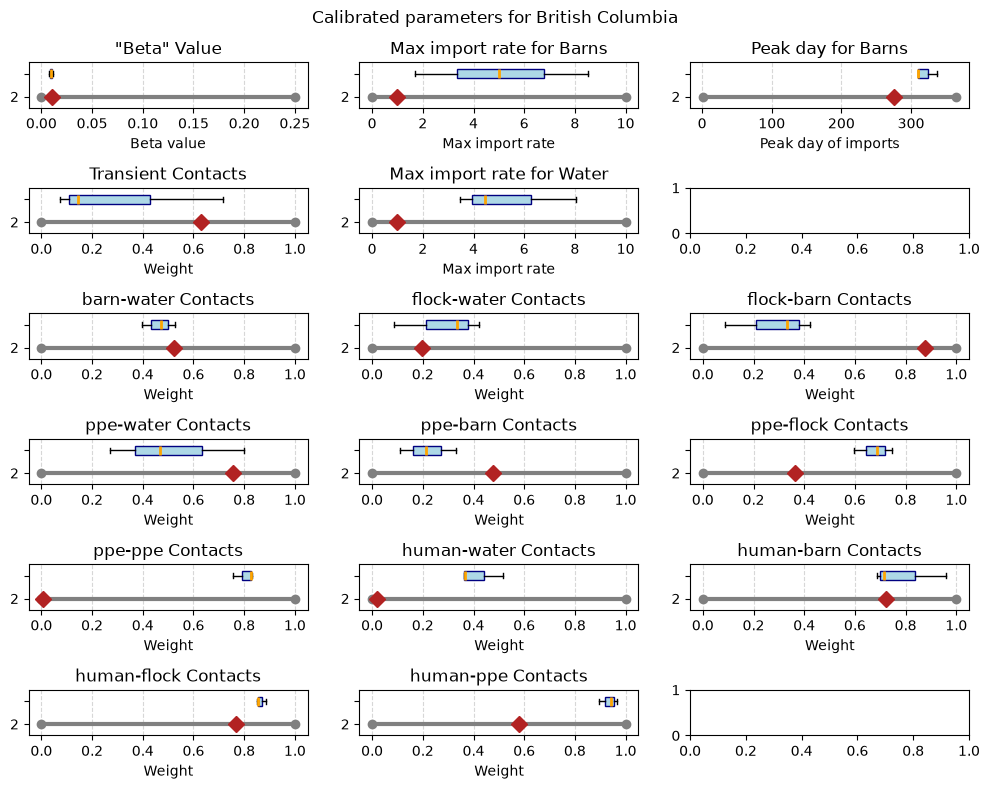

C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

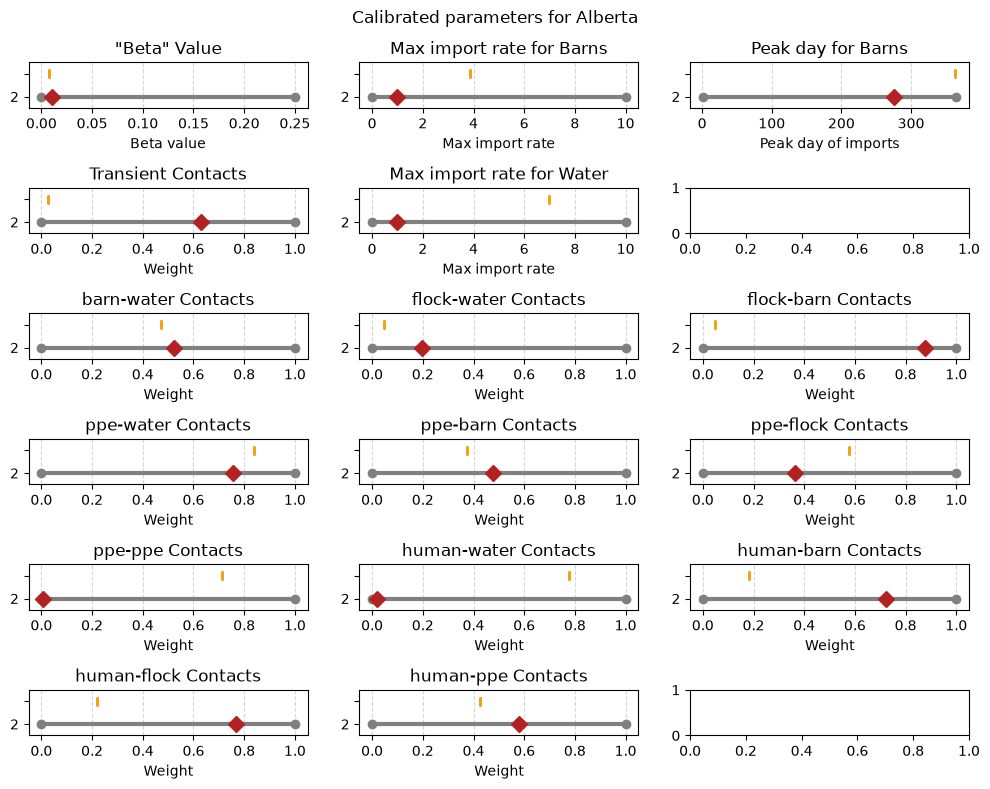

C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

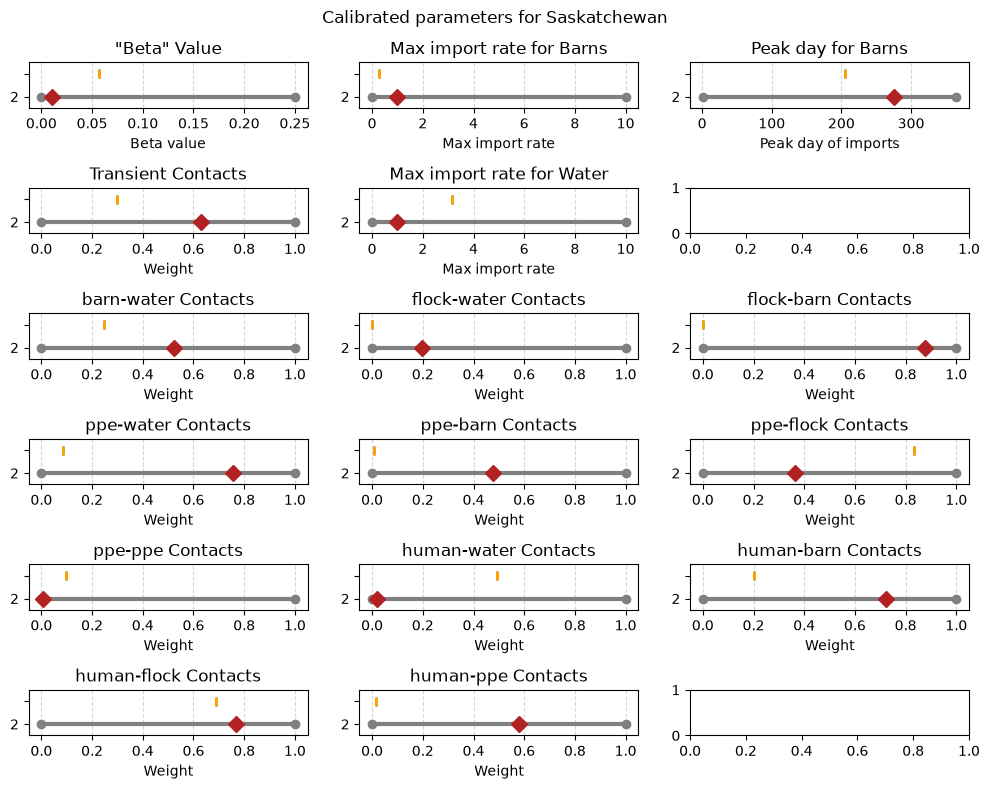

C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

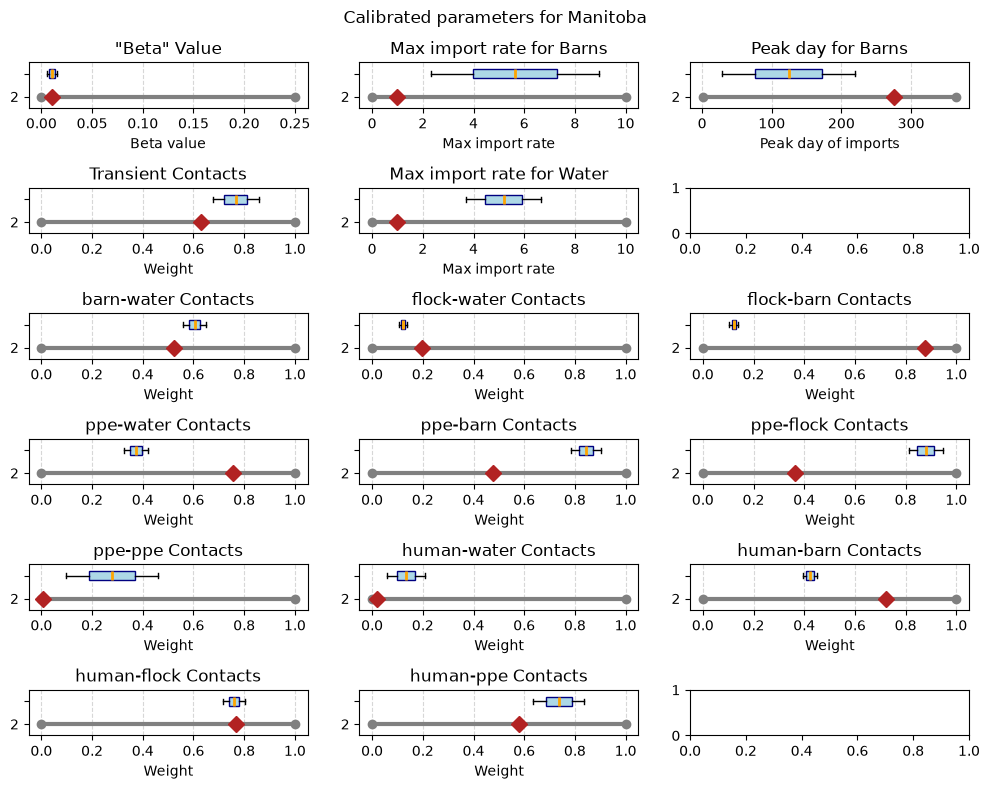

C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

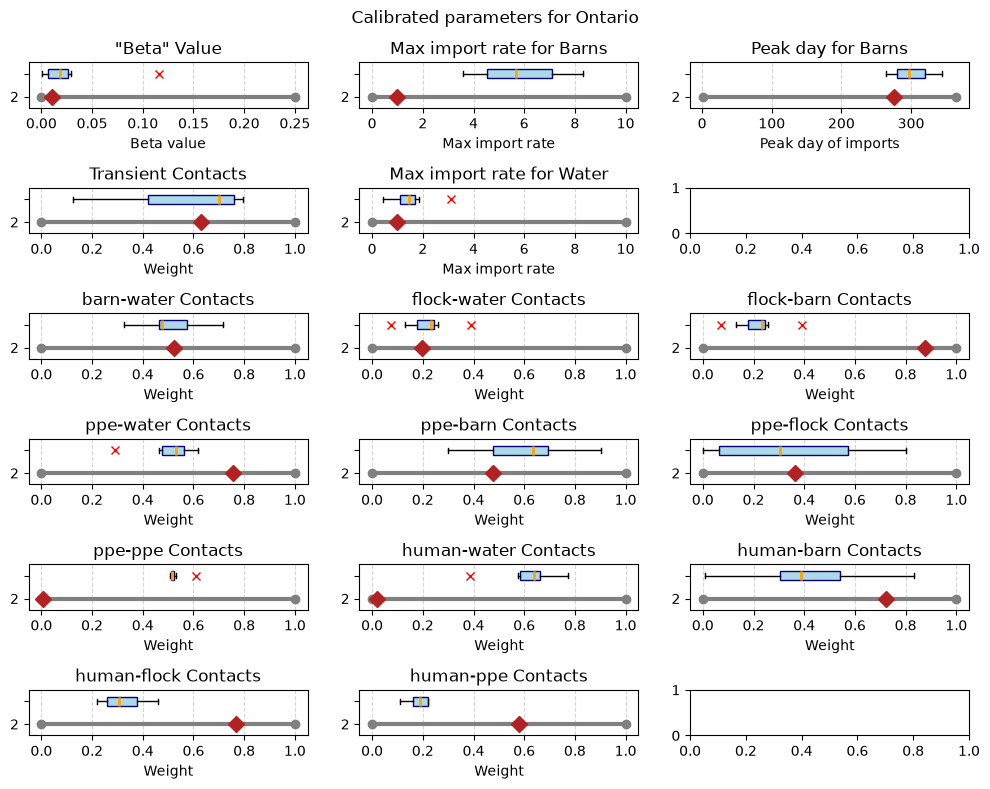

C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

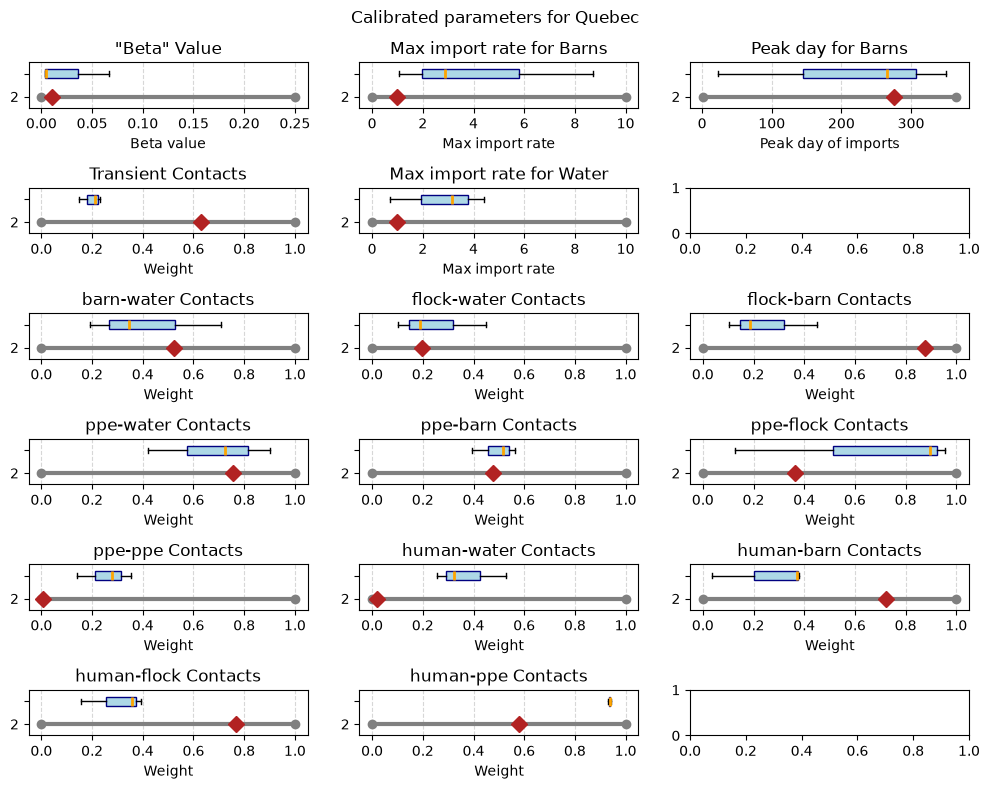

C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:27: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\3929741279.py:45: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(provincial_resu

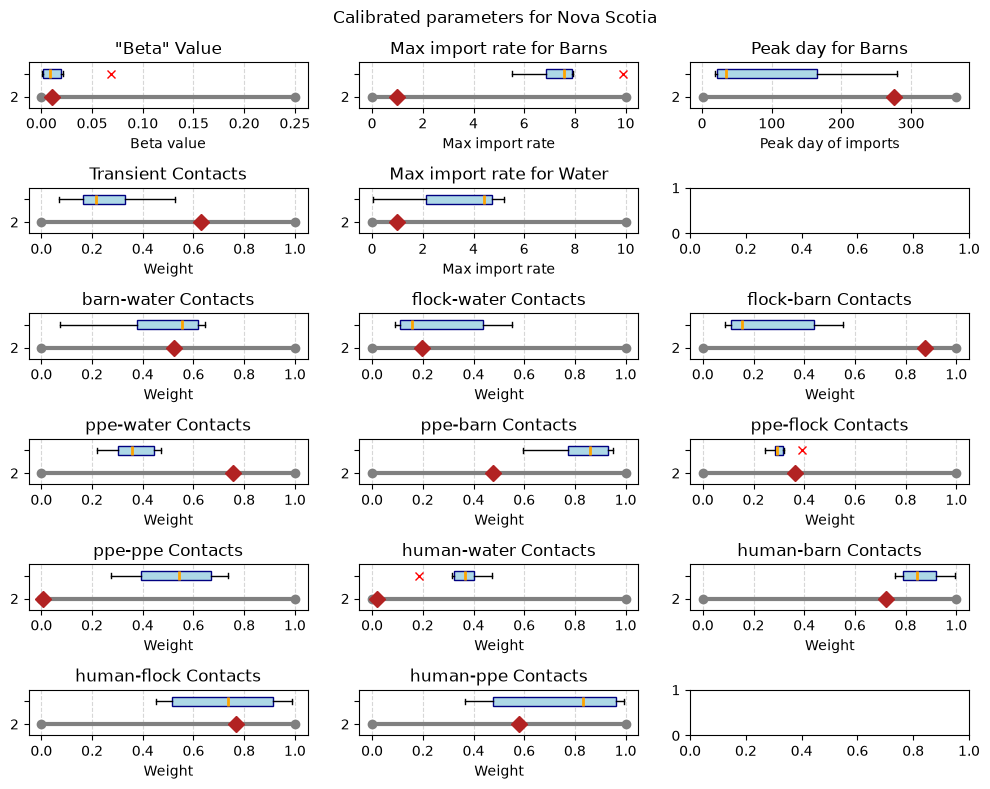

In [ ]:
for province in provincial_results.keys():
    fig, axs = plt.subplots(nrows = 6, ncols = 3, figsize=(10, 8), layout = 'constrained')
    fig.suptitle(f"Calibrated parameters for {province}")
    # Beta
    axs[0,0].hlines(y=1, xmin=calibration_pars['beta']['human'][1], xmax=calibration_pars['beta']['human'][2], colors='gray', linewidth=3, label='Beta range')
    axs[0,0].plot(calibration_pars['beta']['human'][1], 1, 'o', color='gray') # Cap start
    axs[0,0].plot(calibration_pars['beta']['human'][2], 1, 'o', color='gray') # Cap end
    axs[0,0].plot(calibration_pars['beta']['human'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta']['human'][0]})')
    axs[0,0].boxplot(provincial_results[province]['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[0,0].set_ylim(0.5, 2.5)
    axs[0,0].set_yticks([1, 2])
    #axs[0,0].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[0,0].set_xlabel('Beta value')
    axs[0,0].set_title('"Beta" Value')
    axs[0,0].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[0,0].legend(loc='lower left')

    # Barn: max import rate

    axs[0,1].hlines(y=1, xmin=calibration_pars['n_imports']['barn']['max_import_rate'][1], xmax=calibration_pars['n_imports']['barn']['max_import_rate'][2], colors='gray', linewidth=3, label='Max import rate range')
    axs[0,1].plot(calibration_pars['n_imports']['barn']['max_import_rate'][1], 1, 'o', color='gray') # Cap start
    axs[0,1].plot(calibration_pars['n_imports']['barn']['max_import_rate'][2], 1, 'o', color='gray') # Cap end
    axs[0,1].plot(calibration_pars['n_imports']['barn']['max_import_rate'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['barn']['max_import_rate'][0]})')
    axs[0,1].boxplot(provincial_results[province]['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='orange', linewidth=2),
            flierprops=dict(marker='x', markeredgecolor='red'))
    axs[0,1].set_ylim(0.5, 2.5)
    axs[0,1].set_yticks([1, 2])
    #axs[0,1].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[0,1].set_xlabel('Max import rate')
    axs[0,1].set_title('Max import rate for Barns')
    axs[0,1].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[0,1].legend(loc='lower left')

    # Barn: peak day

    axs[0,2].hlines(y=1, xmin=calibration_pars['n_imports']['barn']['peak_day'][1], xmax=calibration_pars['n_imports']['barn']['peak_day'][2], colors='gray', linewidth=3, label='Peak day of imports range')
    axs[0,2].plot(calibration_pars['n_imports']['barn']['peak_day'][1], 1, 'o', color='gray') # Cap start
    axs[0,2].plot(calibration_pars['n_imports']['barn']['peak_day'][2], 1, 'o', color='gray') # Cap end
    axs[0,2].plot(calibration_pars['n_imports']['barn']['peak_day'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['barn']['peak_day'][0]})')
    axs[0,2].boxplot(provincial_results[province]['n_imports']['barn']['peak_day'], vert=False, positions=[2], widths=0.4, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='orange', linewidth=2),
            flierprops=dict(marker='x', markeredgecolor='red'))
    axs[0,2].set_ylim(0.5, 2.5)
    axs[0,2].set_yticks([1, 2])
    #axs[0,2].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[0,2].set_xlabel('Peak day of imports')
    axs[0,2].set_title('Peak day for Barns')
    axs[0,2].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[0,2].legend(loc='lower left')

    # Water: max import rate
    
    axs[1,1].hlines(y=1, xmin=calibration_pars['n_imports']['water']['max_import_rate'][1], xmax=calibration_pars['n_imports']['water']['max_import_rate'][2], colors='gray', linewidth=3, label='Max import rate range')
    axs[1,1].plot(calibration_pars['n_imports']['water']['max_import_rate'][1], 1, 'o', color='gray') # Cap start
    axs[1,1].plot(calibration_pars['n_imports']['water']['max_import_rate'][2], 1, 'o', color='gray') # Cap end
    axs[1,1].plot(calibration_pars['n_imports']['water']['max_import_rate'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['water']['max_import_rate'][0]})')
    axs[1,1].boxplot(provincial_results[province]['n_imports']['water']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='orange', linewidth=2),
            flierprops=dict(marker='x', markeredgecolor='red'))
    axs[1,1].set_ylim(0.5, 2.5)
    axs[1,1].set_yticks([1, 2])
    #axs[1,1].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[1,1].set_xlabel('Max import rate')
    axs[1,1].set_title('Max import rate for Water')
    axs[1,1].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[1,1].legend(loc='lower left')

    # Water: peak day
    # Water peak day is the same as for barns
#     axs[1,2].hlines(y=1, xmin=calibration_pars['n_imports']['water']['peak_day'][1], xmax=calibration_pars['n_imports']['water']['peak_day'][2], colors='gray', linewidth=3, label='Peak day of imports range')
#     axs[1,2].plot(calibration_pars['n_imports']['water']['peak_day'][1], 1, 'o', color='gray') # Cap start
#     axs[1,2].plot(calibration_pars['n_imports']['water']['peak_day'][2], 1, 'o', color='gray') # Cap end
#     axs[1,2].plot(calibration_pars['n_imports']['water']['peak_day'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['water']['peak_day'][0]})')
#     axs[1,2].boxplot(provincial_results[province]['n_imports']['water']['peak_day'], vert=False, positions=[2], widths=0.4, patch_artist=True,
#             boxprops=dict(facecolor='lightblue', color='navy'),
#             medianprops=dict(color='orange', linewidth=2),
#             flierprops=dict(marker='x', markeredgecolor='red'))
#     axs[1,2].set_ylim(0.5, 2.5)
#     axs[1,2].set_yticks([1, 2])
#     axs[1,2].set_yticklabels(['Initial Range', 'Calibrated values'])
#     axs[1,2].set_xlabel('Peak day of imports')
#     axs[1,2].set_title('Calibrated "Peak day" Values for Water vs Initial Range and Seed')
#     axs[1,2].grid(axis='x', linestyle='--', alpha=0.5)
#     axs[1,2].legend(loc='lower left')

    # transient weight

    axs[1,0].hlines(y=1, xmin=calibration_pars['beta_layer']['transient'][1], xmax=calibration_pars['beta_layer']['transient'][2], colors='gray', linewidth=3, label='Transient weight')
    axs[1,0].plot(calibration_pars['beta_layer']['transient'][1], 1, 'o', color='gray') # Cap start
    axs[1,0].plot(calibration_pars['beta_layer']['transient'][2], 1, 'o', color='gray') # Cap end
    axs[1,0].plot(calibration_pars['beta_layer']['transient'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['transient'][0]})')
    axs[1,0].boxplot(provincial_results[province]['beta_layer']['transient'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[1,0].set_ylim(0.5, 2.5)
    axs[1,0].set_yticks([1, 2])
    #axs[1,0].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[1,0].set_xlabel('Weight')
    axs[1,0].set_title('Transient Contacts')
    axs[1,0].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[1,0].legend(loc='lower left')

    #  barn_water weight

    axs[2,0].hlines(y=1, xmin=calibration_pars['beta_layer']['barn_water'][1], xmax=calibration_pars['beta_layer']['barn_water'][2], colors='gray', linewidth=3, label='Barn water contact weight')
    axs[2,0].plot(calibration_pars['beta_layer']['barn_water'][1], 1, 'o', color='gray') # Cap start
    axs[2,0].plot(calibration_pars['beta_layer']['barn_water'][2], 1, 'o', color='gray') # Cap end
    axs[2,0].plot(calibration_pars['beta_layer']['barn_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['barn_water'][0]})')
    axs[2,0].boxplot(provincial_results[province]['beta_layer']['barn_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[2,0].set_ylim(0.5, 2.5)
    axs[2,0].set_yticks([1, 2])
    #axs[2,0].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[2,0].set_xlabel('Weight')
    axs[2,0].set_title('barn-water Contacts')
    axs[2,0].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[2,0].legend(loc='lower left')

    #  flock_water weight

    axs[2,1].hlines(y=1, xmin=calibration_pars['beta_layer']['flock_water'][1], xmax=calibration_pars['beta_layer']['flock_water'][2], colors='gray', linewidth=3, label='Flock water contact weight')
    axs[2,1].plot(calibration_pars['beta_layer']['flock_water'][1], 1, 'o', color='gray') # Cap start
    axs[2,1].plot(calibration_pars['beta_layer']['flock_water'][2], 1, 'o', color='gray') # Cap end
    axs[2,1].plot(calibration_pars['beta_layer']['flock_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['flock_water'][0]})')
    axs[2,1].boxplot(provincial_results[province]['beta_layer']['flock_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[2,1].set_ylim(0.5, 2.5)
    axs[2,1].set_yticks([1, 2])
    #axs[2,1].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[2,1].set_xlabel('Weight')
    axs[2,1].set_title('flock-water Contacts')
    axs[2,1].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[2,1].legend(loc='lower left')

    #  flock_barn weight

    axs[2,2].hlines(y=1, xmin=calibration_pars['beta_layer']['flock_barn'][1], xmax=calibration_pars['beta_layer']['flock_barn'][2], colors='gray', linewidth=3, label='Flock barn contact weight')
    axs[2,2].plot(calibration_pars['beta_layer']['flock_barn'][1], 1, 'o', color='gray') # Cap start
    axs[2,2].plot(calibration_pars['beta_layer']['flock_barn'][2], 1, 'o', color='gray') # Cap end
    axs[2,2].plot(calibration_pars['beta_layer']['flock_barn'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['flock_barn'][0]})')
    axs[2,2].boxplot(provincial_results[province]['beta_layer']['flock_barn'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[2,2].set_ylim(0.5, 2.5)
    axs[2,2].set_yticks([1, 2])
    #axs[2,2].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[2,2].set_xlabel('Weight')
    axs[2,2].set_title('flock-barn Contacts')
    axs[2,2].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[2,2].legend(loc='lower left')

    #  ppe_water weight

    axs[3,0].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_water'][1], xmax=calibration_pars['beta_layer']['ppe_water'][2], colors='gray', linewidth=3, label='PPE water contact weight')
    axs[3,0].plot(calibration_pars['beta_layer']['ppe_water'][1], 1, 'o', color='gray') # Cap start
    axs[3,0].plot(calibration_pars['beta_layer']['ppe_water'][2], 1, 'o', color='gray') # Cap end
    axs[3,0].plot(calibration_pars['beta_layer']['ppe_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_water'][0]})')
    axs[3,0].boxplot(provincial_results[province]['beta_layer']['ppe_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[3,0].set_ylim(0.5, 2.5)
    axs[3,0].set_yticks([1, 2])
    #axs[3,0].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[3,0].set_xlabel('Weight')
    axs[3,0].set_title('ppe-water Contacts')
    axs[3,0].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[3,0].legend(loc='lower left')

    #  ppe_barn weight

    axs[3,1].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_barn'][1], xmax=calibration_pars['beta_layer']['ppe_barn'][2], colors='gray', linewidth=3, label='PPE barn contact weight')
    axs[3,1].plot(calibration_pars['beta_layer']['ppe_barn'][1], 1, 'o', color='gray') # Cap start
    axs[3,1].plot(calibration_pars['beta_layer']['ppe_barn'][2], 1, 'o', color='gray') # Cap end
    axs[3,1].plot(calibration_pars['beta_layer']['ppe_barn'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_barn'][0]})')
    axs[3,1].boxplot(provincial_results[province]['beta_layer']['ppe_barn'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[3,1].set_ylim(0.5, 2.5)
    axs[3,1].set_yticks([1, 2])
    #axs[3,1].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[3,1].set_xlabel('Weight')
    axs[3,1].set_title('ppe-barn Contacts')
    axs[3,1].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[3,1].legend(loc='lower left')

    #  ppe_flock weight

    axs[3,2].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_flock'][1], xmax=calibration_pars['beta_layer']['ppe_flock'][2], colors='gray', linewidth=3, label='PPE flock contact weight')
    axs[3,2].plot(calibration_pars['beta_layer']['ppe_flock'][1], 1, 'o', color='gray') # Cap start
    axs[3,2].plot(calibration_pars['beta_layer']['ppe_flock'][2], 1, 'o', color='gray') # Cap end
    axs[3,2].plot(calibration_pars['beta_layer']['ppe_flock'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_flock'][0]})')
    axs[3,2].boxplot(provincial_results[province]['beta_layer']['ppe_flock'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[3,2].set_ylim(0.5, 2.5)
    axs[3,2].set_yticks([1, 2])
    #axs[3,2].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[3,2].set_xlabel('Weight')
    axs[3,2].set_title('ppe-flock Contacts')
    axs[3,2].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[3,2].legend(loc='lower left')

    #  ppe_ppe weight

    axs[4,0].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_ppe'][1], xmax=calibration_pars['beta_layer']['ppe_ppe'][2], colors='gray', linewidth=3, label='PPE ppe contact weight')
    axs[4,0].plot(calibration_pars['beta_layer']['ppe_ppe'][1], 1, 'o', color='gray') # Cap start
    axs[4,0].plot(calibration_pars['beta_layer']['ppe_ppe'][2], 1, 'o', color='gray') # Cap end
    axs[4,0].plot(calibration_pars['beta_layer']['ppe_ppe'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_ppe'][0]})')
    axs[4,0].boxplot(provincial_results[province]['beta_layer']['ppe_ppe'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[4,0].set_ylim(0.5, 2.5)
    axs[4,0].set_yticks([1, 2])
    #axs[4,0].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[4,0].set_xlabel('Weight')
    axs[4,0].set_title('ppe-ppe Contacts')
    axs[4,0].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[4,0].legend(loc='lower left')

    #  human_water weight

    axs[4,1].hlines(y=1, xmin=calibration_pars['beta_layer']['human_water'][1], xmax=calibration_pars['beta_layer']['human_water'][2], colors='gray', linewidth=3, label='Human water contact weight')
    axs[4,1].plot(calibration_pars['beta_layer']['human_water'][1], 1, 'o', color='gray') # Cap start
    axs[4,1].plot(calibration_pars['beta_layer']['human_water'][2], 1, 'o', color='gray') # Cap end
    axs[4,1].plot(calibration_pars['beta_layer']['human_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_water'][0]})')
    axs[4,1].boxplot(provincial_results[province]['beta_layer']['human_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[4,1].set_ylim(0.5, 2.5)
    axs[4,1].set_yticks([1, 2])
    #axs[4,1].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[4,1].set_xlabel('Weight')
    axs[4,1].set_title('human-water Contacts')
    axs[4,1].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[4,1].legend(loc='lower left')

    #  human_barn weight

    axs[4,2].hlines(y=1, xmin=calibration_pars['beta_layer']['human_barn'][1], xmax=calibration_pars['beta_layer']['human_barn'][2], colors='gray', linewidth=3, label='Human barn contact weight')
    axs[4,2].plot(calibration_pars['beta_layer']['human_barn'][1], 1, 'o', color='gray') # Cap start
    axs[4,2].plot(calibration_pars['beta_layer']['human_barn'][2], 1, 'o', color='gray') # Cap end
    axs[4,2].plot(calibration_pars['beta_layer']['human_barn'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_barn'][0]})')
    axs[4,2].boxplot(provincial_results[province]['beta_layer']['human_barn'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[4,2].set_ylim(0.5, 2.5)
    axs[4,2].set_yticks([1, 2])
    #axs[4,2].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[4,2].set_xlabel('Weight')
    axs[4,2].set_title('human-barn Contacts')
    axs[4,2].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[4,2].legend(loc='lower left')

    #  human_flock weight

    axs[5,0].hlines(y=1, xmin=calibration_pars['beta_layer']['human_flock'][1], xmax=calibration_pars['beta_layer']['human_flock'][2], colors='gray', linewidth=3, label='Human flock contact weight')
    axs[5,0].plot(calibration_pars['beta_layer']['human_flock'][1], 1, 'o', color='gray') # Cap start
    axs[5,0].plot(calibration_pars['beta_layer']['human_flock'][2], 1, 'o', color='gray') # Cap end
    axs[5,0].plot(calibration_pars['beta_layer']['human_flock'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_flock'][0]})')
    axs[5,0].boxplot(provincial_results[province]['beta_layer']['human_flock'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[5,0].set_ylim(0.5, 2.5)
    axs[5,0].set_yticks([1, 2])
    #axs[5,0].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[5,0].set_xlabel('Weight')
    axs[5,0].set_title('human-flock Contacts')
    axs[5,0].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[5,0].legend(loc='lower left')

    #  human_ppe weight

    axs[5,1].hlines(y=1, xmin=calibration_pars['beta_layer']['human_ppe'][1], xmax=calibration_pars['beta_layer']['human_ppe'][2], colors='gray', linewidth=3, label='Human ppe contact weight')
    axs[5,1].plot(calibration_pars['beta_layer']['human_ppe'][1], 1, 'o', color='gray') # Cap start
    axs[5,1].plot(calibration_pars['beta_layer']['human_ppe'][2], 1, 'o', color='gray') # Cap end
    axs[5,1].plot(calibration_pars['beta_layer']['human_ppe'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_ppe'][0]})')
    axs[5,1].boxplot(provincial_results[province]['beta_layer']['human_ppe'], vert=False, positions=[2], widths=0.4, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='navy'),
           medianprops=dict(color='orange', linewidth=2),
           flierprops=dict(marker='x', markeredgecolor='red'))
    axs[5,1].set_ylim(0.5, 2.5)
    axs[5,1].set_yticks([1, 2])
    #axs[5,1].set_yticklabels(['Initial Range', 'Calibrated values'])
    axs[5,1].set_xlabel('Weight')
    axs[5,1].set_title('human-ppe Contacts')
    axs[5,1].grid(axis='x', linestyle='--', alpha=0.5)
    #axs[5,1].legend(loc='lower left')

    #  human_human weight
    #  Unused since there is no human to human transmission in these models
#     axs[5,2].hlines(y=1, xmin=calibration_pars['beta_layer']['human_human'][1], xmax=calibration_pars['beta_layer']['barn_water'][2], colors='gray', linewidth=3, label='Human human contact weight')
#     axs[5,2].plot(calibration_pars['beta_layer']['human_human'][1], 1, 'o', color='gray') # Cap start
#     axs[5,2].plot(calibration_pars['beta_layer']['human_human'][2], 1, 'o', color='gray') # Cap end
#     axs[5,2].plot(calibration_pars['beta_layer']['human_human'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_human'][0]})')
#     axs[5,2].boxplot(provincial_results[province]['beta_layer']['human_human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
#            boxprops=dict(facecolor='lightblue', color='navy'),
#            medianprops=dict(color='orange', linewidth=2),
#            flierprops=dict(marker='x', markeredgecolor='red'))
#     axs[5,2].set_ylim(0.5, 2.5)
#     axs[5,2].set_yticks([1, 2])
#     axs[5,2].set_yticklabels(['Initial Range', 'Calibrated values'])
#     axs[5,2].set_xlabel('Contact weight')
#     axs[5,2].set_title('Calibrated "human human" Contact Weights vs Initial Range and Seed')
#     axs[5,2].grid(axis='x', linestyle='--', alpha=0.5)
#     axs[5,2].legend(loc='lower left')

    plt.tight_layout()
    plt.show()





C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\1446530192.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,0].boxplot(collective_results['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\1446530192.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,1].boxplot(collective_results['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
C:\Users\Darren Flynn\AppData\Local\Temp\ipykernel_13436\1446530192.py:50: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axs[0,2].boxplot(collective_results['n_imports']['b

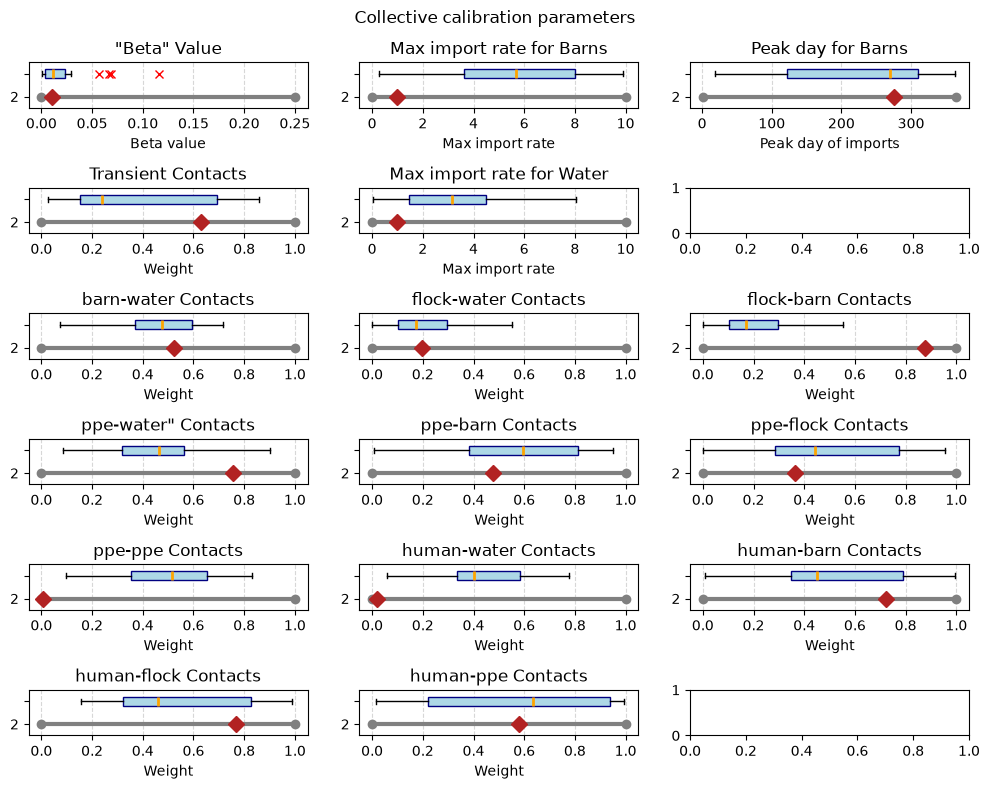

In [ ]:
collective_results_list = []
for province in provincial_results.keys():
    collective_results_list.append(provincial_results[province])

collective_results = json_to_dict(merge_dicts(collective_results_list))

fig, axs = plt.subplots(nrows = 6, ncols = 3, figsize=(10, 8), layout = 'constrained')
fig.suptitle(f"Collective calibration parameters")
    # Beta
axs[0,0].hlines(y=1, xmin=calibration_pars['beta']['human'][1], xmax=calibration_pars['beta']['human'][2], colors='gray', linewidth=3, label='Beta range')
axs[0,0].plot(calibration_pars['beta']['human'][1], 1, 'o', color='gray') # Cap start
axs[0,0].plot(calibration_pars['beta']['human'][2], 1, 'o', color='gray') # Cap end
axs[0,0].plot(calibration_pars['beta']['human'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta']['human'][0]})')
axs[0,0].boxplot(collective_results['beta']['human'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[0,0].set_ylim(0.5, 2.5)
axs[0,0].set_yticks([1, 2])
#axs[0,0].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[0,0].set_xlabel('Beta value')
axs[0,0].set_title('"Beta" Value')
axs[0,0].grid(axis='x', linestyle='--', alpha=0.5)
#axs[0,0].legend(loc='lower left')

    # Barn: max import rate

axs[0,1].hlines(y=1, xmin=calibration_pars['n_imports']['barn']['max_import_rate'][1], xmax=calibration_pars['n_imports']['barn']['max_import_rate'][2], colors='gray', linewidth=3, label='Max import rate range')
axs[0,1].plot(calibration_pars['n_imports']['barn']['max_import_rate'][1], 1, 'o', color='gray') # Cap start
axs[0,1].plot(calibration_pars['n_imports']['barn']['max_import_rate'][2], 1, 'o', color='gray') # Cap end
axs[0,1].plot(calibration_pars['n_imports']['barn']['max_import_rate'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['barn']['max_import_rate'][0]})')
axs[0,1].boxplot(collective_results['n_imports']['barn']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
        boxprops=dict(facecolor='lightblue', color='navy'),
        medianprops=dict(color='orange', linewidth=2),
        flierprops=dict(marker='x', markeredgecolor='red'))
axs[0,1].set_ylim(0.5, 2.5)
axs[0,1].set_yticks([1, 2])
#axs[0,1].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[0,1].set_xlabel('Max import rate')
axs[0,1].set_title('Max import rate for Barns')
axs[0,1].grid(axis='x', linestyle='--', alpha=0.5)
#axs[0,1].legend(loc='lower left')

    # Barn: peak day

axs[0,2].hlines(y=1, xmin=calibration_pars['n_imports']['barn']['peak_day'][1], xmax=calibration_pars['n_imports']['barn']['peak_day'][2], colors='gray', linewidth=3, label='Peak day of imports range')
axs[0,2].plot(calibration_pars['n_imports']['barn']['peak_day'][1], 1, 'o', color='gray') # Cap start
axs[0,2].plot(calibration_pars['n_imports']['barn']['peak_day'][2], 1, 'o', color='gray') # Cap end
axs[0,2].plot(calibration_pars['n_imports']['barn']['peak_day'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['barn']['peak_day'][0]})')
axs[0,2].boxplot(collective_results['n_imports']['barn']['peak_day'], vert=False, positions=[2], widths=0.4, patch_artist=True,
        boxprops=dict(facecolor='lightblue', color='navy'),
        medianprops=dict(color='orange', linewidth=2),
        flierprops=dict(marker='x', markeredgecolor='red'))
axs[0,2].set_ylim(0.5, 2.5)
axs[0,2].set_yticks([1, 2])
#axs[0,2].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[0,2].set_xlabel('Peak day of imports')
axs[0,2].set_title('Peak day for Barns')
axs[0,2].grid(axis='x', linestyle='--', alpha=0.5)
#axs[0,2].legend(loc='lower left')

    # Water: max import rate
    
axs[1,1].hlines(y=1, xmin=calibration_pars['n_imports']['water']['max_import_rate'][1], xmax=calibration_pars['n_imports']['water']['max_import_rate'][2], colors='gray', linewidth=3, label='Max import rate range')
axs[1,1].plot(calibration_pars['n_imports']['water']['max_import_rate'][1], 1, 'o', color='gray') # Cap start
axs[1,1].plot(calibration_pars['n_imports']['water']['max_import_rate'][2], 1, 'o', color='gray') # Cap end
axs[1,1].plot(calibration_pars['n_imports']['water']['max_import_rate'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['n_imports']['water']['max_import_rate'][0]})')
axs[1,1].boxplot(collective_results['n_imports']['water']['max_import_rate'], vert=False, positions=[2], widths=0.4, patch_artist=True,
        boxprops=dict(facecolor='lightblue', color='navy'),
        medianprops=dict(color='orange', linewidth=2),
        flierprops=dict(marker='x', markeredgecolor='red'))
axs[1,1].set_ylim(0.5, 2.5)
axs[1,1].set_yticks([1, 2])
#axs[1,1].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[1,1].set_xlabel('Max import rate')
axs[1,1].set_title('Max import rate for Water')
axs[1,1].grid(axis='x', linestyle='--', alpha=0.5)
#axs[1,1].legend(loc='lower left')


    # transient weight

axs[1,0].hlines(y=1, xmin=calibration_pars['beta_layer']['transient'][1], xmax=calibration_pars['beta_layer']['transient'][2], colors='gray', linewidth=3, label='Transient weight')
axs[1,0].plot(calibration_pars['beta_layer']['transient'][1], 1, 'o', color='gray') # Cap start
axs[1,0].plot(calibration_pars['beta_layer']['transient'][2], 1, 'o', color='gray') # Cap end
axs[1,0].plot(calibration_pars['beta_layer']['transient'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['transient'][0]})')
axs[1,0].boxplot(collective_results['beta_layer']['transient'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[1,0].set_ylim(0.5, 2.5)
axs[1,0].set_yticks([1, 2])
#axs[1,0].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[1,0].set_xlabel('Weight')
axs[1,0].set_title('Transient Contacts')
axs[1,0].grid(axis='x', linestyle='--', alpha=0.5)
#axs[1,0].legend(loc='lower left')

    #  barn_water weight

axs[2,0].hlines(y=1, xmin=calibration_pars['beta_layer']['barn_water'][1], xmax=calibration_pars['beta_layer']['barn_water'][2], colors='gray', linewidth=3, label='Barn water contact weight')
axs[2,0].plot(calibration_pars['beta_layer']['barn_water'][1], 1, 'o', color='gray') # Cap start
axs[2,0].plot(calibration_pars['beta_layer']['barn_water'][2], 1, 'o', color='gray') # Cap end
axs[2,0].plot(calibration_pars['beta_layer']['barn_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['barn_water'][0]})')
axs[2,0].boxplot(collective_results['beta_layer']['barn_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[2,0].set_ylim(0.5, 2.5)
axs[2,0].set_yticks([1, 2])
#axs[2,0].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[2,0].set_xlabel('Weight')
axs[2,0].set_title('barn-water Contacts')
axs[2,0].grid(axis='x', linestyle='--', alpha=0.5)
#axs[2,0].legend(loc='lower left')

    #  flock_water weight

axs[2,1].hlines(y=1, xmin=calibration_pars['beta_layer']['flock_water'][1], xmax=calibration_pars['beta_layer']['flock_water'][2], colors='gray', linewidth=3, label='Flock water contact weight')
axs[2,1].plot(calibration_pars['beta_layer']['flock_water'][1], 1, 'o', color='gray') # Cap start
axs[2,1].plot(calibration_pars['beta_layer']['flock_water'][2], 1, 'o', color='gray') # Cap end
axs[2,1].plot(calibration_pars['beta_layer']['flock_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['flock_water'][0]})')
axs[2,1].boxplot(collective_results['beta_layer']['flock_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[2,1].set_ylim(0.5, 2.5)
axs[2,1].set_yticks([1, 2])
#axs[2,1].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[2,1].set_xlabel('Weight')
axs[2,1].set_title('flock-water Contacts')
axs[2,1].grid(axis='x', linestyle='--', alpha=0.5)
#axs[2,1].legend(loc='lower left')

    #  flock_barn weight

axs[2,2].hlines(y=1, xmin=calibration_pars['beta_layer']['flock_barn'][1], xmax=calibration_pars['beta_layer']['flock_barn'][2], colors='gray', linewidth=3, label='Flock barn contact weight')
axs[2,2].plot(calibration_pars['beta_layer']['flock_barn'][1], 1, 'o', color='gray') # Cap start
axs[2,2].plot(calibration_pars['beta_layer']['flock_barn'][2], 1, 'o', color='gray') # Cap end
axs[2,2].plot(calibration_pars['beta_layer']['flock_barn'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['flock_barn'][0]})')
axs[2,2].boxplot(collective_results['beta_layer']['flock_barn'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[2,2].set_ylim(0.5, 2.5)
axs[2,2].set_yticks([1, 2])
#axs[2,2].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[2,2].set_xlabel('Weight')
axs[2,2].set_title('flock-barn Contacts')
axs[2,2].grid(axis='x', linestyle='--', alpha=0.5)
#axs[2,2].legend(loc='lower left')

    #  ppe_water weight

axs[3,0].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_water'][1], xmax=calibration_pars['beta_layer']['ppe_water'][2], colors='gray', linewidth=3, label='PPE water contact weight')
axs[3,0].plot(calibration_pars['beta_layer']['ppe_water'][1], 1, 'o', color='gray') # Cap start
axs[3,0].plot(calibration_pars['beta_layer']['ppe_water'][2], 1, 'o', color='gray') # Cap end
axs[3,0].plot(calibration_pars['beta_layer']['ppe_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_water'][0]})')
axs[3,0].boxplot(collective_results['beta_layer']['ppe_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[3,0].set_ylim(0.5, 2.5)
axs[3,0].set_yticks([1, 2])
#axs[3,0].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[3,0].set_xlabel('Weight')
axs[3,0].set_title('ppe-water" Contacts')
axs[3,0].grid(axis='x', linestyle='--', alpha=0.5)
#axs[3,0].legend(loc='lower left')

    #  ppe_barn weight

axs[3,1].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_barn'][1], xmax=calibration_pars['beta_layer']['ppe_barn'][2], colors='gray', linewidth=3, label='PPE barn contact weight')
axs[3,1].plot(calibration_pars['beta_layer']['ppe_barn'][1], 1, 'o', color='gray') # Cap start
axs[3,1].plot(calibration_pars['beta_layer']['ppe_barn'][2], 1, 'o', color='gray') # Cap end
axs[3,1].plot(calibration_pars['beta_layer']['ppe_barn'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_barn'][0]})')
axs[3,1].boxplot(collective_results['beta_layer']['ppe_barn'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[3,1].set_ylim(0.5, 2.5)
axs[3,1].set_yticks([1, 2])
#axs[3,1].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[3,1].set_xlabel('Weight')
axs[3,1].set_title('ppe-barn Contacts')
axs[3,1].grid(axis='x', linestyle='--', alpha=0.5)
#axs[3,1].legend(loc='lower left')

    #  ppe_flock weight

axs[3,2].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_flock'][1], xmax=calibration_pars['beta_layer']['ppe_flock'][2], colors='gray', linewidth=3, label='PPE flock contact weight')
axs[3,2].plot(calibration_pars['beta_layer']['ppe_flock'][1], 1, 'o', color='gray') # Cap start
axs[3,2].plot(calibration_pars['beta_layer']['ppe_flock'][2], 1, 'o', color='gray') # Cap end
axs[3,2].plot(calibration_pars['beta_layer']['ppe_flock'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_flock'][0]})')
axs[3,2].boxplot(collective_results['beta_layer']['ppe_flock'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[3,2].set_ylim(0.5, 2.5)
axs[3,2].set_yticks([1, 2])
#axs[3,2].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[3,2].set_xlabel('Weight')
axs[3,2].set_title('ppe-flock Contacts')
axs[3,2].grid(axis='x', linestyle='--', alpha=0.5)
#axs[3,2].legend(loc='lower left')

    #  ppe_ppe weight

axs[4,0].hlines(y=1, xmin=calibration_pars['beta_layer']['ppe_ppe'][1], xmax=calibration_pars['beta_layer']['ppe_ppe'][2], colors='gray', linewidth=3, label='PPE ppe contact weight')
axs[4,0].plot(calibration_pars['beta_layer']['ppe_ppe'][1], 1, 'o', color='gray') # Cap start
axs[4,0].plot(calibration_pars['beta_layer']['ppe_ppe'][2], 1, 'o', color='gray') # Cap end
axs[4,0].plot(calibration_pars['beta_layer']['ppe_ppe'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['ppe_ppe'][0]})')
axs[4,0].boxplot(collective_results['beta_layer']['ppe_ppe'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[4,0].set_ylim(0.5, 2.5)
axs[4,0].set_yticks([1, 2])
#axs[4,0].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[4,0].set_xlabel('Weight')
axs[4,0].set_title('ppe-ppe Contacts')
axs[4,0].grid(axis='x', linestyle='--', alpha=0.5)
#axs[4,0].legend(loc='lower left')

    #  human_water weight

axs[4,1].hlines(y=1, xmin=calibration_pars['beta_layer']['human_water'][1], xmax=calibration_pars['beta_layer']['human_water'][2], colors='gray', linewidth=3, label='Human water contact weight')
axs[4,1].plot(calibration_pars['beta_layer']['human_water'][1], 1, 'o', color='gray') # Cap start
axs[4,1].plot(calibration_pars['beta_layer']['human_water'][2], 1, 'o', color='gray') # Cap end
axs[4,1].plot(calibration_pars['beta_layer']['human_water'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_water'][0]})')
axs[4,1].boxplot(collective_results['beta_layer']['human_water'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[4,1].set_ylim(0.5, 2.5)
axs[4,1].set_yticks([1, 2])
#axs[4,1].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[4,1].set_xlabel('Weight')
axs[4,1].set_title('human-water Contacts')
axs[4,1].grid(axis='x', linestyle='--', alpha=0.5)
#axs[4,1].legend(loc='lower left')

    #  human_barn weight

axs[4,2].hlines(y=1, xmin=calibration_pars['beta_layer']['human_barn'][1], xmax=calibration_pars['beta_layer']['human_barn'][2], colors='gray', linewidth=3, label='Human barn contact weight')
axs[4,2].plot(calibration_pars['beta_layer']['human_barn'][1], 1, 'o', color='gray') # Cap start
axs[4,2].plot(calibration_pars['beta_layer']['human_barn'][2], 1, 'o', color='gray') # Cap end
axs[4,2].plot(calibration_pars['beta_layer']['human_barn'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_barn'][0]})')
axs[4,2].boxplot(collective_results['beta_layer']['human_barn'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[4,2].set_ylim(0.5, 2.5)
axs[4,2].set_yticks([1, 2])
#axs[4,2].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[4,2].set_xlabel('Weight')
axs[4,2].set_title('human-barn Contacts')
axs[4,2].grid(axis='x', linestyle='--', alpha=0.5)
#axs[4,2].legend(loc='lower left')

    #  human_flock weight

axs[5,0].hlines(y=1, xmin=calibration_pars['beta_layer']['human_flock'][1], xmax=calibration_pars['beta_layer']['human_flock'][2], colors='gray', linewidth=3, label='Human flock contact weight')
axs[5,0].plot(calibration_pars['beta_layer']['human_flock'][1], 1, 'o', color='gray') # Cap start
axs[5,0].plot(calibration_pars['beta_layer']['human_flock'][2], 1, 'o', color='gray') # Cap end
axs[5,0].plot(calibration_pars['beta_layer']['human_flock'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_flock'][0]})')
axs[5,0].boxplot(collective_results['beta_layer']['human_flock'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[5,0].set_ylim(0.5, 2.5)
axs[5,0].set_yticks([1, 2])
#axs[5,0].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[5,0].set_xlabel('Weight')
axs[5,0].set_title('human-flock Contacts')
axs[5,0].grid(axis='x', linestyle='--', alpha=0.5)
#axs[5,0].legend(loc='lower left')

    #  human_ppe weight

axs[5,1].hlines(y=1, xmin=calibration_pars['beta_layer']['human_ppe'][1], xmax=calibration_pars['beta_layer']['human_ppe'][2], colors='gray', linewidth=3, label='Human ppe contact weight')
axs[5,1].plot(calibration_pars['beta_layer']['human_ppe'][1], 1, 'o', color='gray') # Cap start
axs[5,1].plot(calibration_pars['beta_layer']['human_ppe'][2], 1, 'o', color='gray') # Cap end
axs[5,1].plot(calibration_pars['beta_layer']['human_ppe'][0], 1, marker='D', color='firebrick', markersize=8, label=f'Seed Value ({calibration_pars['beta_layer']['human_ppe'][0]})')
axs[5,1].boxplot(collective_results['beta_layer']['human_ppe'], vert=False, positions=[2], widths=0.4, patch_artist=True,
       boxprops=dict(facecolor='lightblue', color='navy'),
       medianprops=dict(color='orange', linewidth=2),
       flierprops=dict(marker='x', markeredgecolor='red'))
axs[5,1].set_ylim(0.5, 2.5)
axs[5,1].set_yticks([1, 2])
#axs[5,1].set_yticklabels(['Initial Range', 'Calibrated values'])
axs[5,1].set_xlabel('Weight')
axs[5,1].set_title('human-ppe Contacts')
axs[5,1].grid(axis='x', linestyle='--', alpha=0.5)
#axs[5,1].legend(loc='lower left')

plt.tight_layout()
plt.show()